In [20]:
import sys
import os

In [21]:
project_root = os.path.abspath(os.path.join(os.getcwd(), "..", "..", ".."))

if project_root not in sys.path:
    sys.path.append(project_root)

In [22]:
import torch
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
        
from core.models import GetModel
import json

In [23]:
def GetModelFromConfig(path):
    config_path =  "config.json"
    with open(config_path, "r") as f:
        config = json.load(f)
                
    model = GetModel(config)
    
    return model, config["experiment"]["N"]

In [24]:
import plotly.graph_objects as go
from sklearn.decomposition import PCA
import numpy as np

def plot_input_only_plotly(model, N):
    weights = model.tokens_embed.weight.detach().cpu().numpy()

    offset = 2 * N * N 
    labels = np.arange(-N, N + 1)
    indices = labels + offset
    
    valid_indices = [i for i in indices if 0 <= i < weights.shape[0]]
    input_weights = weights[valid_indices]
    labels = labels[:len(valid_indices)]
    
    pca = PCA(n_components=2)
    embeds_2d = pca.fit_transform(input_weights)
    

    fig = go.Figure()
    
    fig.add_trace(go.Scatter(
        x=embeds_2d[:, 0],
        y=embeds_2d[:, 1],
        mode='markers+text',
        text=[str(l) for l in labels],
        textposition="top center",
        marker=dict(
            size=14,
            color='red',
            line=dict(width=1, color='black')
        ),
        hoverinfo='text',
        hovertext=[f"Wartość wejściowa: {l}<br>Index w embed: {l + offset}" for l in labels]
    ))
    
    fig.update_layout(
        title=f"Struktura liczb wejściowych (Embeddings) dla N={N}",
        xaxis_title="PCA Component 1",
        yaxis_title="PCA Component 2",
        plot_bgcolor='white',
        width=700,
        height=700
    )
    
    fig.update_xaxes(showgrid=True, gridcolor='lightgray')
    fig.update_yaxes(showgrid=True, gridcolor='lightgray')
    
    fig.show()

In [25]:
model, N = GetModelFromConfig("")

model_path = r"checkpoint_epoch_14000.pt"

checkpoint = torch.load(model_path, map_location="cpu")

model_weights = checkpoint["model_state_dict"]
model.load_state_dict(model_weights)

plot_input_only_plotly(model, N=N)

In [ ]:
import torch
import pandas as pd
import plotly.express as px
from sklearn.decomposition import PCA

def plot_embeddings_3d(model, title="Osadzenia Wejściowe 3D"):
    embeddings = model.tokens_embed.weight.detach().cpu().numpy()
    
    pca = PCA(n_components=3)
    embeddings_3d = pca.fit_transform(embeddings)
    
    num_tokens = embeddings.shape[0]
    labels = [str(i - num_tokens//2) for i in range(num_tokens)] 
    
    values = [abs(i - num_tokens//2) for i in range(num_tokens)]
    
    df = pd.DataFrame({
        'PCA 1': embeddings_3d[:, 0],
        'PCA 2': embeddings_3d[:, 1],
        'PCA 3': embeddings_3d[:, 2],
        'Token': labels,
        'Wartość': values
    })
    
    fig = px.scatter_3d(
        df, 
        x='PCA 1', 
        y='PCA 2', 
        z='PCA 3',
        text='Token',
        color='Wartość',
        color_continuous_scale='Viridis',
        title=title
    )
    
    fig.update_traces(
        marker=dict(size=5, line=dict(width=1, color='DarkSlateGrey')),
        textposition='top center'
    )
    
    fig.show()


plot_embeddings_3d(model)

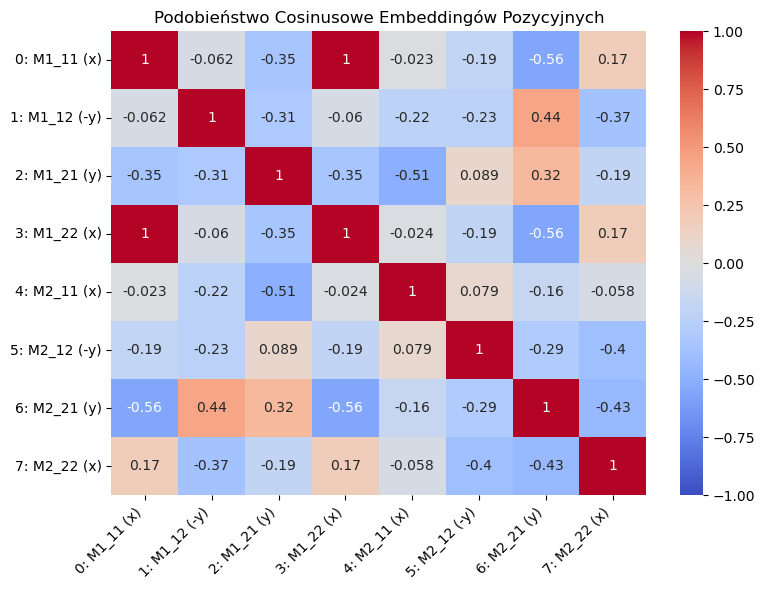

In [27]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

def analyze_positional_embeddings(model):
    pos_weights = model.pos_embed.weight.detach().cpu().numpy()
    
    norm = np.linalg.norm(pos_weights, axis=1, keepdims=True)
    normalized_pos = pos_weights / norm
    
    cosine_sim = np.dot(normalized_pos, normalized_pos.T)
    
    plt.figure(figsize=(8, 6))
    

    labels = [
        '0: M1_11 (x)', '1: M1_12 (-y)', '2: M1_21 (y)', '3: M1_22 (x)',
        '4: M2_11 (x)', '5: M2_12 (-y)', '6: M2_21 (y)', '7: M2_22 (x)'
    ]
    
    sns.heatmap(
        cosine_sim, 
        annot=True, 
        cmap="coolwarm", 
        xticklabels=labels, 
        yticklabels=labels,
        vmin=-1, vmax=1
    )
    
    plt.title("Podobieństwo Cosinusowe Embeddingów Pozycyjnych")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()


analyze_positional_embeddings(model)

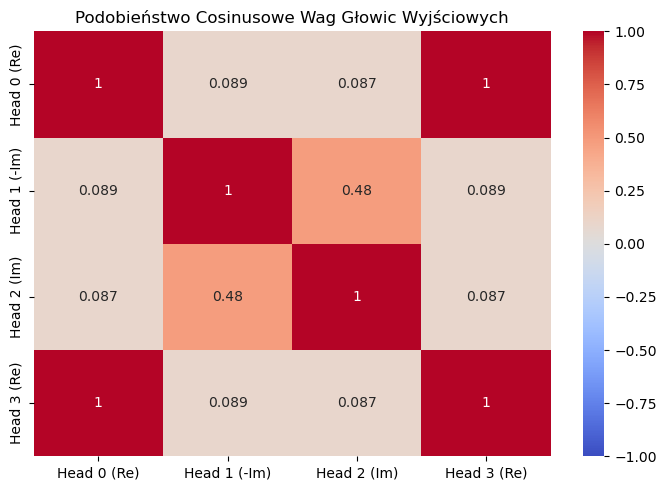

In [28]:
import torch
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

def analyze_output_heads(model):
    heads_weights = [head.weight.detach().cpu().numpy() for head in model.output_heads]
    
    flat_heads = [w.flatten() for w in heads_weights]
    flat_heads = np.array(flat_heads) 
    
    norm = np.linalg.norm(flat_heads, axis=1, keepdims=True)
    normalized_heads = flat_heads / norm
    head_sim = np.dot(normalized_heads, normalized_heads.T)
    
    labels = ['Head 0 (Re)', 'Head 1 (-Im)', 'Head 2 (Im)', 'Head 3 (Re)']
    
    plt.figure(figsize=(7, 5))
    sns.heatmap(
        head_sim, 
        annot=True, 
        cmap="coolwarm", 
        xticklabels=labels, 
        yticklabels=labels,
        vmin=-1, vmax=1
    )
    plt.title("Podobieństwo Cosinusowe Wag Głowic Wyjściowych")
    plt.tight_layout()
    plt.show()

analyze_output_heads(model)

In [29]:
import numpy as np
import plotly.graph_objects as go
from sklearn.decomposition import PCA

def plot_output_head_plotly(model, N, head_idx=0):
    """
    Rysuje interaktywny wykres 2D PCA dla wybranej głowicy wyjściowej.
    head_idx: 0 -> Re (górna lewa), 1 -> -Im (górna prawa), 2 -> Im (dolna lewa), 3 -> Re (dolna prawa)
    """
    # Wyciągamy wagi konkretnej głowicy z nn.ModuleList
    weights = model.output_heads[head_idx].weight.detach().cpu().numpy()
    
    # Nasz zsynchronizowany offset w nowym datasiecie
    output_offset = 2 * N * N
    min_val, max_val = -2 * N * N, 2 * N * N
    active_indices = []
    labels = []
    
    for val in range(min_val, max_val + 1):
        idx = val + output_offset
        if 0 <= idx < weights.shape[0]:
            active_indices.append(idx)
            labels.append(val)

    active_weights = weights[active_indices]

    # Twój filtr normy, usuwający słabo aktywne tokeny krańcowe
    weight_norms = np.linalg.norm(active_weights, axis=1)
    valid_mask = weight_norms > 0.0
    
    active_weights = active_weights[valid_mask]
    labels = np.array(labels)[valid_mask]

    # Redukcja wymiarowości wag do 2D
    pca = PCA(n_components=2)
    embeds_2d = pca.fit_transform(active_weights)
    
    # Mapowanie nazw głowic do tytułu wykresu
    head_names = {0: "Re (Head 0)", 1: "-Im (Head 1)", 2: "Im (Head 2)", 3: "Re (Head 3)"}
    title_name = head_names.get(head_idx, f"Head {head_idx}")

    fig = go.Figure()

    fig.add_trace(go.Scatter(
        x=embeds_2d[:, 0],
        y=embeds_2d[:, 1],
        mode='markers+text',
        text=[str(l) for l in labels],
        textposition="top right",
        textfont=dict(size=10, family="Arial Black"),
        marker=dict(
            size=12,
            color=labels,
            colorscale='RdBu',
            showscale=True,
            colorbar=dict(title=f"Wartość {title_name.split()[0]}"),
            line=dict(width=1, color='Black')
        ),
        hoverinfo='text',
        hovertext=[f"Token ID: {l + output_offset}<br>Wartość algebraiczna: {l}" for l in labels]
    ))

    fig.update_layout(
        title=dict(
            text=f"Interaktywna struktura wyjść dla {title_name} (N={N})",
            x=0.5,
            xanchor='center'
        ),
        xaxis=dict(title="PCA Component 1", gridcolor='rgba(200,200,200,0.2)'),
        yaxis=dict(title="PCA Component 2", gridcolor='rgba(200,200,200,0.2)'),
        plot_bgcolor='white',
        paper_bgcolor='white',
        width=900,
        height=800,
        showlegend=False
    )
    
    fig.show()

In [30]:
# Wizualizacja pierwszej głowicy rzeczywistej (Head 0)
plot_output_head_plotly(model, N=N, head_idx=0)

plot_output_head_plotly(model, N=N, head_idx=1)

# Wizualizacja głowicy urojonej (Head 2)
plot_output_head_plotly(model, N=N, head_idx=2)

plot_output_head_plotly(model, N=N, head_idx=3)


In [31]:
import numpy as np
import plotly.graph_objects as go
from sklearn.decomposition import PCA

def plot_output_head_plotly_3d(model, N, head_idx=0):
    """
    Rysuje interaktywny wykres 3D PCA dla wybranej głowicy wyjściowej.
    head_idx: 0 -> Re, 1 -> -Im, 2 -> Im, 3 -> Re
    """
    # Wyciągamy wagi konkretnej głowicy
    weights = model.output_heads[head_idx].weight.detach().cpu().numpy()
    
    # Zsynchronizowany offset
    output_offset = 2 * N * N
    min_val, max_val = -2 * N * N, 2 * N * N
    active_indices = []
    labels = []
    
    for val in range(min_val, max_val + 1):
        idx = val + output_offset
        if 0 <= idx < weights.shape[0]:
            active_indices.append(idx)
            labels.append(val)

    active_weights = weights[active_indices]

    # Filtr aktywności tokenów krańcowych
    weight_norms = np.linalg.norm(active_weights, axis=1)
    valid_mask = weight_norms > 0.4
    
    active_weights = active_weights[valid_mask]
    labels = np.array(labels)[valid_mask]

    # Redukcja wymiarowości wag do 3D
    pca = PCA(n_components=3)
    embeds_3d = pca.fit_transform(active_weights)
    
    # Mapowanie nazw głowic
    head_names = {0: "Re (Head 0)", 1: "-Im (Head 1)", 2: "Im (Head 2)", 3: "Re (Head 3)"}
    title_name = head_names.get(head_idx, f"Head {head_idx}")

    fig = go.Figure()

    fig.add_trace(go.Scatter3d(
        x=embeds_3d[:, 0],
        y=embeds_3d[:, 1],
        z=embeds_3d[:, 2],
        mode='markers+text',
        text=[str(l) for l in labels],
        textposition="top right",
        textfont=dict(size=9, family="Arial Black"),
        marker=dict(
            size=6,
            color=labels,
            colorscale='RdBu',
            showscale=True,
            colorbar=dict(title=f"Wartość {title_name.split()[0]}"),
            line=dict(width=1, color='Black')
        ),
        hoverinfo='text',
        hovertext=[f"Token ID: {l + output_offset}<br>Wartość algebraiczna: {l}" for l in labels]
    ))

    fig.update_layout(
        title=dict(
            text=f"Interaktywna struktura 3D wyjść dla {title_name} (N={N})",
            x=0.5,
            xanchor='center'
        ),
        scene=dict(
            xaxis=dict(title="PCA 1", backgroundcolor="white", gridcolor="rgba(200,200,200,0.2)"),
            yaxis=dict(title="PCA 2", backgroundcolor="white", gridcolor="rgba(200,200,200,0.2)"),
            zaxis=dict(title="PCA 3", backgroundcolor="white", gridcolor="rgba(200,200,200,0.2)"),
        ),
        width=1000,
        height=900,
        showlegend=False
    )
    
    fig.show()

In [32]:
plot_output_head_plotly_3d(model, N=N, head_idx=0)

plot_output_head_plotly_3d(model, N=N, head_idx=2)

In [33]:
import numpy as np
import pandas as pd
import plotly.express as px
from sklearn.decomposition import PCA

def plot_polar_embeddings(model, N):
    voc_size = 4 * N * N + 1

    emb_weights = model.tokens_embed.weight.detach().cpu().numpy()
    pca = PCA(n_components=2)
    embeddings_2d = pca.fit_transform(emb_weights)
    
    x = embeddings_2d[:, 0]
    y = embeddings_2d[:, 1]
    
    # Centerujemy punkty wokół ich środka ciężkości, żeby promień i kąt liczyły się poprawnie
    x_centered = x - np.mean(x)
    y_centered = y - np.mean(y)
    
    # 2. Transformacja kartezjańska -> biegunowa
    r = np.sqrt(x_centered**2 + y_centered**2)
    theta = np.arctan2(y_centered, x_centered) # Wynik w radianach (-pi do pi)
    theta_deg = np.degrees(theta)              # Zamiana na stopnie (-180 do 180)
    
    # Przygotowanie etykiet i kolorowania pod zbiór danych
    labels = [str(i - voc_size//2) for i in range(voc_size)]
    color_values = [i - voc_size//2 for i in range(voc_size)]
    
    df = pd.DataFrame({
        'Kąt (Wielkość obrotu)': theta_deg,
        'Promień (Odległość od środka)': r,
        'Liczba': labels,
        'Wartość Re': color_values
    })
    
    # 3. Wykres we współrzędnych rozwiniętych (Kąt vs Promień)
    # Jeśli model ułożył się w okrąg, tutaj zobaczymy idealnie posortowane linie
    fig = px.scatter(
        df, 
        x='Kąt (Wielkość obrotu)', 
        y='Promień (Odległość od środka)',
        text='Liczba',
        color='Wartość Re',
        color_continuous_scale='RdBu',
        title="Rozwinięcie Biegunowe Osadzeń (Kąt vs Promień)"
    )
    
    fig.update_traces(textposition='top center')
    fig.show()
    
    # 4. Opcjonalnie: Klasyczny wykres na siatce radarowej/polarnej
    fig_radar = px.scatter_polar(
        df, 
        r='Promień (Odległość od środka)', 
        theta='Kąt (Wielkość obrotu)',
        text='Liczba',
        color='Wartość Re',
        color_continuous_scale='RdBu',
        title="Osadzenia na Siatce Biegunowej"
    )
    fig_radar.show()


plot_polar_embeddings(model, N=N)

In [35]:
import numpy as np
import plotly.graph_objects as go
from sklearn.manifold import TSNE

def plot_output_head_tsne(model, N, head_idx=0, perplexity=5, random_state=13):
    """
    Rysuje interaktywny wykres 2D t-SNE dla wybranej głowicy wyjściowej.
    head_idx: 0 -> Re (górna lewa), 1 -> -Im (górna prawa), 2 -> Im (dolna lewa), 3 -> Re (dolna prawa)
    """
    # Wyciągamy wagi konkretnej głowicy z nn.ModuleList (dokładnie jak w Twoim szablonie)
    weights = model.output_heads[head_idx].weight.detach().cpu().numpy()
    
    # Nasz zsynchronizowany offset w nowym datasiecie
    output_offset = 2 * N * N
    min_val, max_val = -2 * N * N, 2 * N * N
    active_indices = []
    labels = []
    
    for val in range(min_val, max_val + 1):
        idx = val + output_offset
        if 0 <= idx < weights.shape[0]:
            active_indices.append(idx)
            labels.append(val)

    active_weights = weights[active_indices]

    # Twój filtr normy, usuwający słabo aktywne tokeny krańcowe
    weight_norms = np.linalg.norm(active_weights, axis=1)
    valid_mask = weight_norms > 0.0
    
    active_weights = active_weights[valid_mask]
    labels = np.array(labels)[valid_mask]

    # Bezpiecznik dla perplexity: t-SNE wymaga, aby perplexity < liczba próbek
    n_samples = active_weights.shape[0]
    actual_perplexity = min(perplexity, max(1, n_samples - 1))

    # Redukcja wymiarowości wag do 2D za pomocą t-SNE (bez parametru n_iter)
    tsne = TSNE(
        n_components=2, 
        perplexity=actual_perplexity, 
        random_state=random_state
    )
    embeds_2d = tsne.fit_transform(active_weights)
    
    # Mapowanie nazw głowic do tytułu wykresu
    head_names = {0: "Re (Head 0)", 1: "-Im (Head 1)", 2: "Im (Head 2)", 3: "Re (Head 3)"}
    title_name = head_names.get(head_idx, f"Head {head_idx}")

    fig = go.Figure()

    fig.add_trace(go.Scatter(
        x=embeds_2d[:, 0],
        y=embeds_2d[:, 1],
        mode='markers+text',
        text=[str(l) for l in labels],
        textposition="top right",
        textfont=dict(size=10, family="Arial Black"),
        marker=dict(
            size=12,
            color=labels,
            colorscale='RdBu',
            showscale=True,
            colorbar=dict(title=f"Wartość {title_name.split()[0]}"),
            line=dict(width=1, color='Black')
        ),
        hoverinfo='text',
        hovertext=[f"Token ID: {l + output_offset}<br>Wartość algebraiczna: {l}" for l in labels]
    ))

    fig.update_layout(
        title=dict(
            text=f"Interaktywna struktura wyjść t-SNE dla {title_name} (N={N})",
            x=0.5,
            xanchor='center'
        ),
        xaxis=dict(title="t-SNE Dimension 1", gridcolor='rgba(200,200,200,0.2)'),
        yaxis=dict(title="t-SNE Dimension 2", gridcolor='rgba(200,200,200,0.2)'),
        plot_bgcolor='white',
        paper_bgcolor='white',
        width=900,
        height=800,
        showlegend=False
    )
    
    fig.show()

plot_output_head_tsne(model, N=N)
plot_output_head_tsne(model, N=N,head_idx=1)